In [30]:
from langgraph.graph import StateGraph, START,END ,MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.messages.utils import trim_messages,count_tokens_approximately,RemoveMessage

In [31]:
llm =  ChatOpenAI(model="gpt-4o-mini")

# TABLE of contents 

### A)  Trimming of data 
- Creating a function that trims the last message 
- Putting the dummy data 
- Showing all the data 

### Deletion  of data 

- Creating a function that deletes the first N  messages
- Putting the dummy data 
- Showing all the data 


# 1)  Trimming of data 

1) **Creating a function that trims the last messages**

![image](./assets/tokens.png)

**NOTE :  `trim_messages` usually changes only what gets sent to the LLM, not what’s stored in the state. The state keeps the full history, and each call to the model gets a trimmed copy.**

In [32]:
MAX_TOKENS =  100

def chat_node(state :  MessagesState):
    
    
    messages =  trim_messages(
        state['messages'],
        max_tokens=MAX_TOKENS,
        token_counter=count_tokens_approximately,
        strategy="last"
    )
    
    result = llm.invoke(messages)
    
    return{"messages":result}


    

In [33]:
graph =  StateGraph(MessagesState)
graph.add_node("chat_node",chat_node)


graph.add_edge(START,"chat_node")
graph.add_edge("chat_node",END)


checkpoiner =  InMemorySaver()

workflow =  graph.compile(checkpointer=checkpoiner)

2)  **Putting dummy content that exceeds 150 tokens intentionally**

In [34]:
## sample convo


config =  {"configurable":{"thread_id":"chat1"}}
result = workflow.invoke(
    {
        "messages": [
            {"role": "user", "content": "I am learning LangGraph."},
            {"role": "assistant", "content": "That's great! LangGraph is a library for building stateful, multi-step applications with LLMs. It models your workflow as a graph of nodes and edges. What would you like to start with?"},
            {"role": "user", "content": "What exactly is a node in LangGraph?"},
            {"role": "assistant", "content": "A node is just a Python function that receives the current state, does some work such as calling an LLM or a tool, and returns an update to the state. Nodes are the building blocks of your graph."},
            {"role": "user", "content": "And how do edges work? Are they just connections between nodes?"},
            {"role": "assistant", "content": "Yes, edges define the flow between nodes. Normal edges always go from one node to the next. Conditional edges use a routing function to decide which node runs next based on the current state, which lets you build loops and branching logic."},
            {"role": "user", "content": "What is the state, and why is it important?"},
            {"role": "assistant", "content": "The state is a shared data structure, usually a TypedDict, that every node reads from and writes to. Reducers like add_messages control how updates are merged, for example appending new messages instead of overwriting the list."},
            {"role": "user", "content": "How does memory work across multiple conversations?"},
            {"role": "assistant", "content": "You attach a checkpointer like MemorySaver when compiling the graph and pass a thread_id in the config. LangGraph saves the state after each step, so later calls with the same thread_id continue where the conversation left off."},
            {"role": "user", "content": "That makes sense. Can you summarize everything I've learned so far in a few bullet points?"},
        ]
    },
    config,
)

result["messages"][-1].content

'Sure! Here’s a summary of what you’ve learned:\n\n- **Checkpointer (MemorySaver)**: A tool used for saving the state of a conversation or process when compiling a graph.\n- **Thread Management**: Each conversation or process can be associated with a unique `thread_id` in the configuration to keep track of its state.\n- **State Persistence**: LangGraph saves the conversation state after each step, allowing for seamless continuation of the conversation in subsequent calls with the same `thread_id`.\n- **Usage of Thread_id**: By using the same `thread_id`, you can ensure that interactions remain consistent and coherent across multiple sessions.\n\nLet me know if you need more details on any specific point!'

3) **Fetching all the content.**

In [35]:
for item in workflow.get_state({"configurable": {"thread_id": "chat1"}}).values['messages']:
    print(item.content)
    print('-'*120)

I am learning LangGraph.
------------------------------------------------------------------------------------------------------------------------
That's great! LangGraph is a library for building stateful, multi-step applications with LLMs. It models your workflow as a graph of nodes and edges. What would you like to start with?
------------------------------------------------------------------------------------------------------------------------
What exactly is a node in LangGraph?
------------------------------------------------------------------------------------------------------------------------
A node is just a Python function that receives the current state, does some work such as calling an LLM or a tool, and returns an update to the state. Nodes are the building blocks of your graph.
------------------------------------------------------------------------------------------------------------------------
And how do edges work? Are they just connections between nodes?
---------

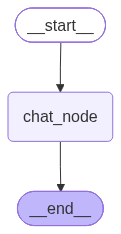

In [36]:

from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

# 2) Deletion of data 

1) **Creating a function that deletes the first N messages**

In [37]:
def chat_node_delete(state :  MessagesState):
    
    ans =  llm.invoke(state["messages"])
    return {"messages":ans}


def delete_old_messages(state: MessagesState):
    msgs = state["messages"]

    # if more than 10 messages, delete the earliest 6
    if len(msgs) > 10:
        to_remove = msgs[:6]
        return {"messages": [RemoveMessage(id=m.id) for m in to_remove]}

    return {}

In [38]:
graph2 =  StateGraph(MessagesState)
graph2.add_node("chat_node_delete",chat_node_delete)
graph2.add_node("clean",delete_old_messages)


graph2.add_edge(START,"chat_node_delete")
graph2.add_edge("chat_node_delete","clean")
graph2.add_edge("clean",END)


checkpoiner =  InMemorySaver()

workflow2 =  graph2.compile(checkpointer=checkpoiner)

2. **putting the dummy data.** 

In [39]:
## sampel convo 


config =  {"configurable":{"thread_id":"chat2"}}
result = workflow2.invoke(
    {
        "messages": [
            {"role": "user", "content": "I am learning LangGraph."},
            {"role": "assistant", "content": "That's great! LangGraph is a library for building stateful, multi-step applications with LLMs. It models your workflow as a graph of nodes and edges. What would you like to start with?"},
            {"role": "user", "content": "What exactly is a node in LangGraph?"},
            {"role": "assistant", "content": "A node is just a Python function that receives the current state, does some work such as calling an LLM or a tool, and returns an update to the state. Nodes are the building blocks of your graph."},
            {"role": "user", "content": "And how do edges work? Are they just connections between nodes?"},
            {"role": "assistant", "content": "Yes, edges define the flow between nodes. Normal edges always go from one node to the next. Conditional edges use a routing function to decide which node runs next based on the current state, which lets you build loops and branching logic."},
            {"role": "user", "content": "What is the state, and why is it important?"},
            {"role": "assistant", "content": "The state is a shared data structure, usually a TypedDict, that every node reads from and writes to. Reducers like add_messages control how updates are merged, for example appending new messages instead of overwriting the list."},
            {"role": "user", "content": "How does memory work across multiple conversations?"},
            {"role": "assistant", "content": "You attach a checkpointer like MemorySaver when compiling the graph and pass a thread_id in the config. LangGraph saves the state after each step, so later calls with the same thread_id continue where the conversation left off."},
            {"role": "user", "content": "That makes sense. Can you summarize everything I've learned so far in a few bullet points?"},
        ]
    },
    config,
)

result["messages"][-1].content

"Certainly! Here’s a summary of what you've learned about LangGraph:\n\n- **Nodes**: Python functions that perform work on the current state and return updates to it. They are the fundamental building blocks of a graph.\n\n- **Edges**: Connections between nodes that define the flow of execution. Normal edges create a linear sequence, while conditional edges allow for branching and control flow based on the current state.\n\n- **State**: A shared data structure that holds the current information throughout the workflow. Nodes read from and update this state, enabling continuity across different steps.\n\n- **Memory**: Managed through a checkpointer like MemorySaver. It allows the graph to save and restore state between conversations based on a unique thread_id, facilitating continuity in multi-turn interactions.\n\nLet me know if you need more details on any of these points or if you have additional questions!"

3. **Fetching all the data.**

In [46]:

snap = workflow2.get_state(config)
print("Stored messages after cleanup:", len(snap.values["messages"]))
print(" -- Messages ---")
for idx,i in enumerate(snap.values["messages"]):
    print(f"{idx+1}) {i.content}" )

Stored messages after cleanup: 6
 -- Messages ---
1) What is the state, and why is it important?
2) The state is a shared data structure, usually a TypedDict, that every node reads from and writes to. Reducers like add_messages control how updates are merged, for example appending new messages instead of overwriting the list.
3) How does memory work across multiple conversations?
4) You attach a checkpointer like MemorySaver when compiling the graph and pass a thread_id in the config. LangGraph saves the state after each step, so later calls with the same thread_id continue where the conversation left off.
5) That makes sense. Can you summarize everything I've learned so far in a few bullet points?
6) Certainly! Here’s a summary of what you've learned about LangGraph:

- **Nodes**: Python functions that perform work on the current state and return updates to it. They are the fundamental building blocks of a graph.

- **Edges**: Connections between nodes that define the flow of executio

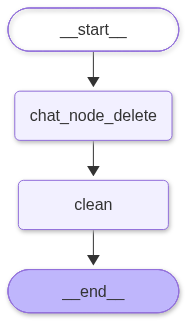

In [41]:

from IPython.display import Image
Image(workflow2.get_graph().draw_mermaid_png())